# Client demo

Demonstrate the use of the Client (Assetto Corsa Sim interface) without the OpenAI Gym interface layer.

In [35]:
%matplotlib inline

import matplotlib.pyplot as plt
import sys
import os
import numpy as np
import pandas as pd
import glob as glob
import time#
import pickle
from omegaconf import OmegaConf

# add custom paths
sys.path.extend([os.path.abspath('./assetto_corsa_gym')])
import AssettoCorsaEnv.assettoCorsa as assettoCorsa

# Configure the logging system
import logging
logger = logging.getLogger(__name__)
logging.basicConfig(
    level=logging.INFO,  # Set the logging level (DEBUG, INFO, WARNING, ERROR, CRITICAL)
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',  # Format of the log messages
    datefmt='%Y-%m-%d %H:%M:%S',  # Format of the timestamp
)


# load config file

In [36]:
config = OmegaConf.load("config.yml")
client = assettoCorsa.make_client_only(config.AssettoCorsa)

# Show static info

In [37]:
static_info = client.simulation_management.get_static_info()
ac_mod_config = client.simulation_management.get_config()

logger.info("Static info:")
for i in static_info:
    logger.info(f"{i}: {static_info[i]}")
logger.info("AC Mod config:")
for i in ac_mod_config:
    logger.info(f"{i}: {ac_mod_config[i]}")


INFO:__main__:Static info:
INFO:__main__:WindDirection: 359
INFO:__main__:LastSplits: [0, 0, 0]
INFO:__main__:isCarInPit: 0
INFO:__main__:CAR_WHEEL_R: [0.26899999380111694, 0.26899999380111694, 0.2784999907016754, 0.2784999907016754]
INFO:__main__:TyreContactPoint_RL: [238.75677490234375, -4.802361011505127, -425.44140625]
INFO:__main__:TrackName: ks_barcelona
INFO:__main__:TyreContactPoint_FR: [235.6870574951172, -4.703734397888184, -426.37371826171875]
INFO:__main__:TrackLength: 4591.88720703125
INFO:__main__:autoShifterOn: 1
INFO:__main__:isCarInPitlane: 0
INFO:__main__:TrackConfiguration: layout_gp
INFO:__main__:CAR_TRACK: 1.5403949056546078
INFO:__main__:TyreContactPoint_FL: [236.03076171875, -4.687112331390381, -424.81610107421875]
INFO:__main__:WorldPosition: [237.48175048828125, -4.478264331817627, -425.953857421875]
INFO:__main__:TyreContactPoint_RR: [238.42535400390625, -4.82037878036499, -426.94561767578125]
INFO:__main__:CAR_WHEELBASE: 2.7991850060783663
INFO:__main__:penal

# Test gear shift

In [38]:
# test gear shifting
client.controls.set_controls(0,-1,1, enable_gear_shift=True, shift_up=True)
client.controls.apply_local_controls()
time.sleep(0.01)
client.controls.set_controls(0,-1,1, enable_gear_shift=True, shift_up=False)
client.controls.apply_local_controls()

time.sleep(1.0)
client.controls.set_controls(0,-1,1, enable_gear_shift=True, shift_down=True)
client.controls.apply_local_controls()
time.sleep(0.01)
client.controls.set_controls(0,-1,1, enable_gear_shift=True, shift_down=False)
client.controls.apply_local_controls()

# Apply actions and recover the car

In [39]:
states = []

client.reset()

# shift up
client.controls.set_controls(0,-1,1, enable_gear_shift=True, shift_up=True)
client.controls.apply_local_controls()
time.sleep(0.01)
client.controls.set_controls(0,-1,1, enable_gear_shift=True, shift_up=False)
client.controls.apply_local_controls()

for i in range(500):
    if i % 2 == 0:
        steer = .1
    else:
        steer = -.1
    client.controls.set_controls(steer=steer, acc=0.5, brake=-1.)
    client.respond_to_server()
    state = client.step_sim()
    states.append(state.copy())
    time.sleep(0.01)

client.controls.set_defaults()
client.respond_to_server()
client.simulation_management.send_reset()
client.close()

INFO:AssettoCorsaEnv.ac_client:sending reset to simulation management server
INFO:AssettoCorsaEnv.ac_client:AC Client. Listening at host: localhost port: 2345
INFO:AssettoCorsaEnv.ac_client:Client connected on 2345
INFO:AssettoCorsaEnv.ac_client:sending reset to simulation management server


# Plot states

In [33]:
df = pd.DataFrame(states)
df.columns

Index(['done', 'Dy_fr', 'accStatus', 'CamberRad', 'rr_wheel_load',
       'NormalizedSplinePosition', 'timestamp_ac', 'tyre_loaded_radius',
       'tyreContactHeading_FL_y', 'fr_tire_temperature_core', 'Dy_fl',
       'LapCount', 'fl_damper_linear_potentiometer', 'penaltyTime', 'Mz',
       'actualGear', 'cgHeight', 'rr_damper_linear_potentiometer',
       'wheel_speed_rr', 'currentTime', 'dynamic_pressure', 'packetId',
       'tyres_load', 'numberOfTyresOut', 'accelY', 'RPM', 'world_position_y',
       'world_position_x', 'world_position_z', 'BestLap',
       'rl_tire_temperature_core', 'accelX', 'tyreContactHeading_RR_z',
       'tyreContactHeading_RR_y', 'tyreContactHeading_RR_x', 'rl_wheel_load',
       'wheel_speed_fl', 'tyreContactHeading_RL_y', 'tyreContactHeading_RL_x',
       'tyreContactHeading_RL_z', 'NdSlip', 'tyreContactHeading_FL_x',
       'tyreContactHeading_FL_z', 'angular_velocity_y', 'angular_velocity_x',
       'angular_velocity_z', 'speed', 'local_velocity_z', 'loc

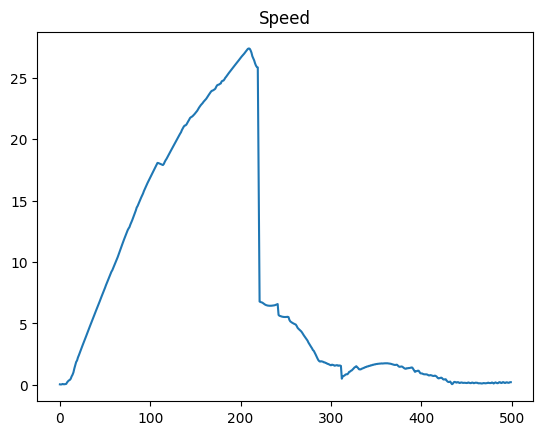

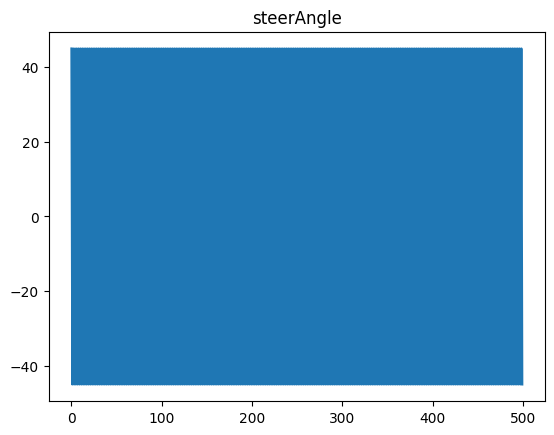

In [34]:
plt.title("Speed")
plt.plot(df.speed)
plt.show()

plt.title("steerAngle")
plt.plot(df.steerAngle)
plt.show()